In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Student Performance Prediction Project")
print("Libraries imported successfully!")

Student Performance Prediction Project
Libraries imported successfully!


# Student Performance Prediction System

## Mini Project – Artificial Intelligence and Machine Learning

### Introduction
This project uses Machine Learning to predict student academic performance based on student-related information.

### Objective
To analyse student data and predict final examination grades using Linear Regression.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
from pathlib import Path

file_path = Path("../Dataset/student-mat.csv")

if not file_path.exists():
    file_path = Path("Dataset/student-mat.csv")

if not file_path.exists():
    file_path = Path("Project_1_Student_Performance/Dataset/student-mat.csv")

if not file_path.exists():
    raise FileNotFoundError("student-mat.csv not found. Check the Dataset folder.")

df = pd.read_csv(file_path, sep=";")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [5]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 395
Number of Columns: 33


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [7]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [8]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [9]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [10]:
print("Average Final Grade:", df["G3"].mean())
print("Highest Final Grade:", df["G3"].max())
print("Lowest Final Grade:", df["G3"].min())

Average Final Grade: 10.415189873417722
Highest Final Grade: 20
Lowest Final Grade: 0


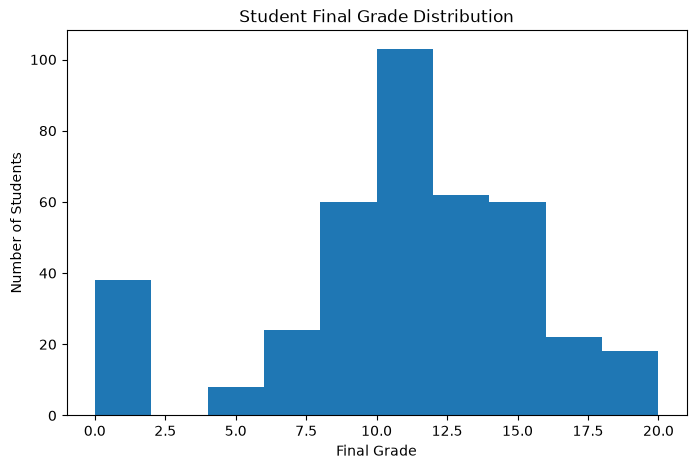

In [11]:
plt.figure(figsize=(8, 5))

plt.hist(df["G3"], bins=10)

plt.title("Student Final Grade Distribution")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()

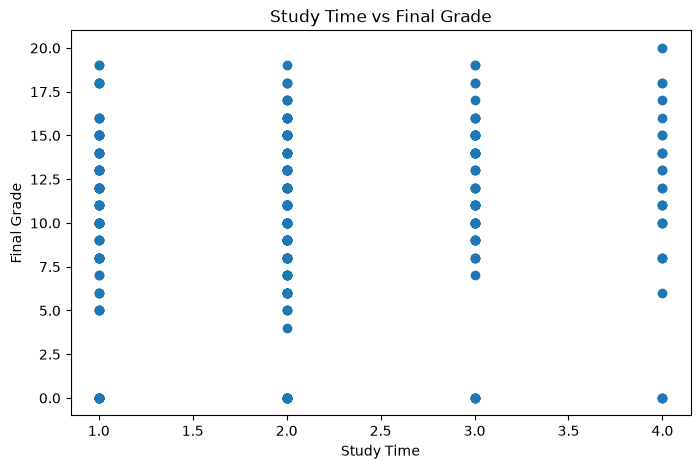

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(df["studytime"], df["G3"])

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time")
plt.ylabel("Final Grade")

plt.show()

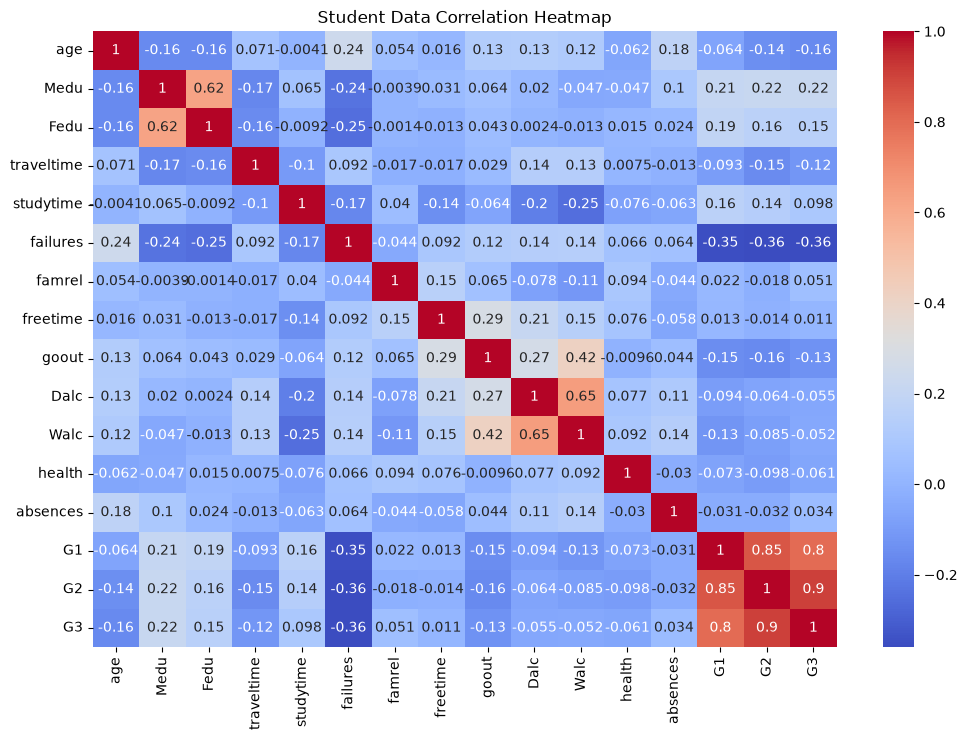

In [13]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Student Data Correlation Heatmap")
plt.show()

In [14]:
from pathlib import Path

graph_folder = Path("../Graphs")

if not graph_folder.exists():
    graph_folder = Path("Graphs")

graph_folder.mkdir(parents=True, exist_ok=True)

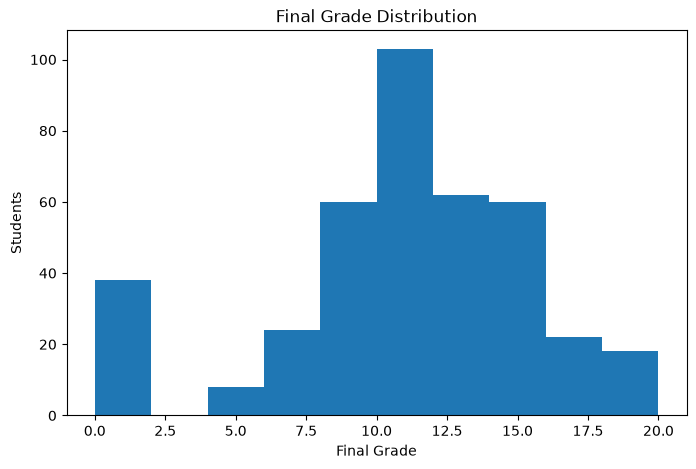

In [15]:
plt.figure(figsize=(8, 5))
plt.hist(df["G3"], bins=10)
plt.title("Final Grade Distribution")
plt.xlabel("Final Grade")
plt.ylabel("Students")

plt.savefig(graph_folder / "grade_distribution.png")
plt.show()

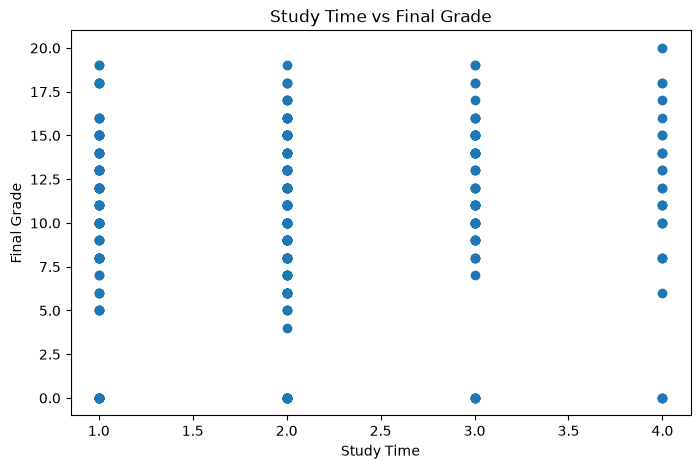

In [16]:
plt.figure(figsize=(8, 5))
plt.scatter(df["studytime"], df["G3"])
plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time")
plt.ylabel("Final Grade")

plt.savefig(graph_folder / "study_time.png")
plt.show()

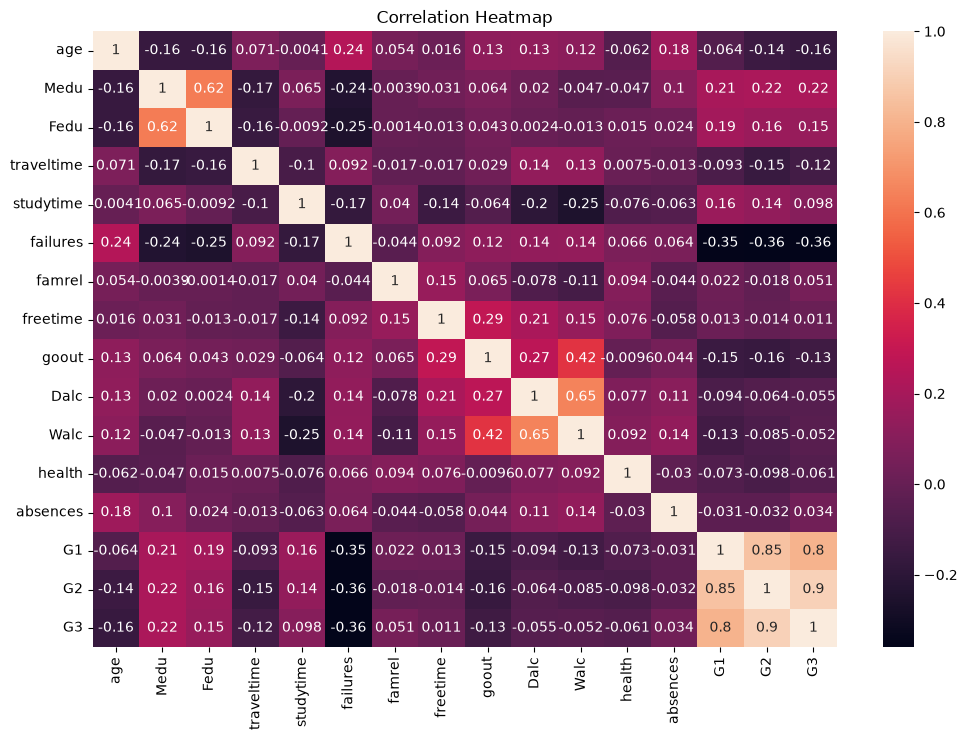

In [17]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True)
plt.title("Correlation Heatmap")

plt.savefig(graph_folder / "correlation.png")
plt.show()

In [18]:
from pathlib import Path

project_folder = file_path.resolve().parent.parent

graph_folder = project_folder / "Graphs"

graph_folder.mkdir(exist_ok=True)

print("Graphs folder ready!")
print("Location:", graph_folder)

Graphs folder ready!
Location: C:\Users\USER\OneDrive\Desktop\AI_ML_MINI_PROJECTS\Project_1_Student_Performance\Graphs


In [19]:
# Feature Selection

X = df.drop(columns=["G1", "G2", "G3"])

y = df["G3"]

print("Input Features:")
print(X.head())

print("\nOutput Features:")
print(y.head())

print("\nInput Shape:", X.shape)
print("Output Shape:", y.shape)

Input Features:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  higher internet  romantic  famrel  freetime goout Dalc Walc health absences  
0    yes       no        no       4         3     4    1    1      3        6  
1    yes      yes        no       5         3     3    1    1      3        4  
2    yes      yes        no       4         3     2    2    3      3       10  
3    yes      yes       yes       3         2     2    1    1      5        2  
4    yes       no        no       4         3     2    1    2      5        4  

[5 rows x 30 col

In [20]:
# Data Preprocessing

X = pd.get_dummies(X, drop_first=True)

print("Data Preprocessing Completed!")

print("Processed Dataset:")
print(X.head())

print("New Input Shape:", X.shape)

Data Preprocessing Completed!
Processed Dataset:
   age  Medu  Fedu  traveltime  studytime  failures  famrel  freetime  goout  \
0   18     4     4           2          2         0       4         3      4   
1   17     1     1           1          2         0       5         3      3   
2   15     1     1           1          2         3       4         3      2   
3   15     4     2           1          3         0       3         2      2   
4   16     3     3           1          2         0       4         3      2   

   Dalc  ...  guardian_mother  guardian_other  schoolsup_yes  famsup_yes  \
0     1  ...             True           False           True       False   
1     1  ...            False           False          False        True   
2     2  ...             True           False           True       False   
3     1  ...             True           False          False        True   
4     1  ...            False           False          False        True   

   paid_yes  

In [21]:
# Train-Test Split

X = X.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Data Splitting Completed!")

Training Data: (316, 39)
Testing Data: (79, 39)
Data Splitting Completed!


In [22]:
# Linear Regression Model

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [23]:
print("Model:", model)
print("Training Completed:", model.coef_.shape)
print("Model Intercept:", model.intercept_)

Model: LinearRegression()
Training Completed: (39,)
Model Intercept: 13.285176723298516


In [24]:
# Predict Student Marks

y_pred = model.predict(X_test)

print("Predicted Marks:")
print(y_pred[:10])

print("\nActual Marks:")
print(y_test.values[:10])

Predicted Marks:
[ 1.88508025  7.45339224  8.30868805 11.55112413 10.20284528  9.43314825
 13.21126069 12.69040139 10.26673682 12.34152834]

Actual Marks:
[10 12  5 10  9 13 18  6  0 14]


In [25]:
# Model Evaluation

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("R2 Score:", r2)

Mean Absolute Error: 3.39526092580192
Mean Squared Error: 17.603737398324718
R2 Score: 0.14149247411195776


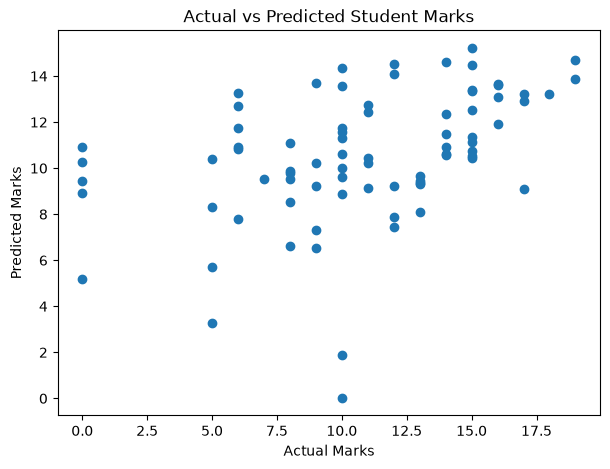

In [26]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Student Marks")

plt.savefig(graph_folder / "actual_vs_predicted.png")

plt.show()

In [27]:
import pickle

with open("../Source_Code/student_model.pkl", "wb") as f:
    pickle.dump(model, f)

print("Model Saved Successfully!")

Model Saved Successfully!


In [28]:
import pickle

with open("../Source_Code/feature_columns.pkl", "wb") as f:
    pickle.dump(X.columns.tolist(), f)

print("Feature Columns Saved Successfully!")

Feature Columns Saved Successfully!
